In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math


In [3]:
raw_data = pd.read_csv("industrial-machine-condition-classification/student_dataset.csv")
test = pd.read_csv("industrial-machine-condition-classification/test.csv")

raw_data.head()

,unit_id,unit_type,ambient_temp,process_temp,coolant_flow,shaft_speed,drive_torque,power_load,component_wear,thermal_stress,mechanical_load,vibration_index,condition
0,UNT-184174,M,21.5,56.4,17.85,1454.0,58.2,9.099,30.0,29.31,57.19,1.768,0
1,UNT-236234,H,29.9,65.0,30.88,1720.0,54.6,10.101,13.0,23.93,36.94,1.081,0
2,UNT-247460,M,26.4,47.8,19.75,1552.0,38.4,6.328,89.0,13.52,38.22,1.031,0
3,UNT-176316,M,28.8,60.9,19.10,1513.0,49.1,7.768,59.0,24.62,46.17,1.011,0
4,UNT-105110,S,29.4,64.0,11.77,1536.0,52.6,8.405,36.0,27.83,94.72,1.851,1


In [4]:
raw_data.shape

(16000, 13)

In [5]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   unit_id          16000 non-null  str    
 1   unit_type        15978 non-null  str    
 2   ambient_temp     15953 non-null  float64
 3   process_temp     15955 non-null  float64
 4   coolant_flow     15939 non-null  float64
 5   shaft_speed      15968 non-null  float64
 6   drive_torque     15964 non-null  float64
 7   power_load       15975 non-null  float64
 8   component_wear   15944 non-null  float64
 9   thermal_stress   15950 non-null  float64
 10  mechanical_load  15955 non-null  float64
 11  vibration_index  15926 non-null  float64
 12  condition        16000 non-null  int64  
dtypes: float64(10), int64(1), str(2)
memory usage: 1.6 MB


In [6]:
raw_data.describe()

,ambient_temp,process_temp,coolant_flow,shaft_speed,drive_torque,power_load,component_wear,thermal_stress,mechanical_load,vibration_index,condition
count,15953.000000,15955.000000,15939.000000,15968.000000,15964.000000,15975.000000,15944.000000,15950.000000,15955.000000,15926.000000,16000.000000
mean,25.981113,60.985653,17.876902,1519.399737,55.029216,8.961852,108.325702,27.674356,72.483153,1.690895,0.750000
std,4.926352,11.098875,6.112769,262.652572,11.448610,3.137047,67.347098,10.805493,24.233399,0.493647,0.829182
min,12.000000,33.600000,7.820000,824.000000,25.100000,2.749000,3.000000,7.360000,25.490000,0.612000,0.000000
25%,22.300000,52.900000,12.380000,1324.000000,46.800000,6.619000,58.000000,19.660000,53.480000,1.337000,0.000000
50%,24.900000,59.800000,17.620000,1496.000000,54.100000,8.444000,94.000000,25.745000,68.090000,1.617000,0.500000
75%,29.900000,67.600000,22.130000,1693.000000,62.400000,10.817000,144.000000,33.760000,88.885000,1.965000,1.250000
max,41.200000,116.900000,37.140000,2574.000000,95.000000,23.956000,340.000000,84.670000,180.420000,5.534000,2.000000


In [7]:
raw_data.head()

,unit_id,unit_type,ambient_temp,process_temp,coolant_flow,shaft_speed,drive_torque,power_load,component_wear,thermal_stress,mechanical_load,vibration_index,condition
0,UNT-184174,M,21.5,56.4,17.85,1454.0,58.2,9.099,30.0,29.31,57.19,1.768,0
1,UNT-236234,H,29.9,65.0,30.88,1720.0,54.6,10.101,13.0,23.93,36.94,1.081,0
2,UNT-247460,M,26.4,47.8,19.75,1552.0,38.4,6.328,89.0,13.52,38.22,1.031,0
3,UNT-176316,M,28.8,60.9,19.10,1513.0,49.1,7.768,59.0,24.62,46.17,1.011,0
4,UNT-105110,S,29.4,64.0,11.77,1536.0,52.6,8.405,36.0,27.83,94.72,1.851,1


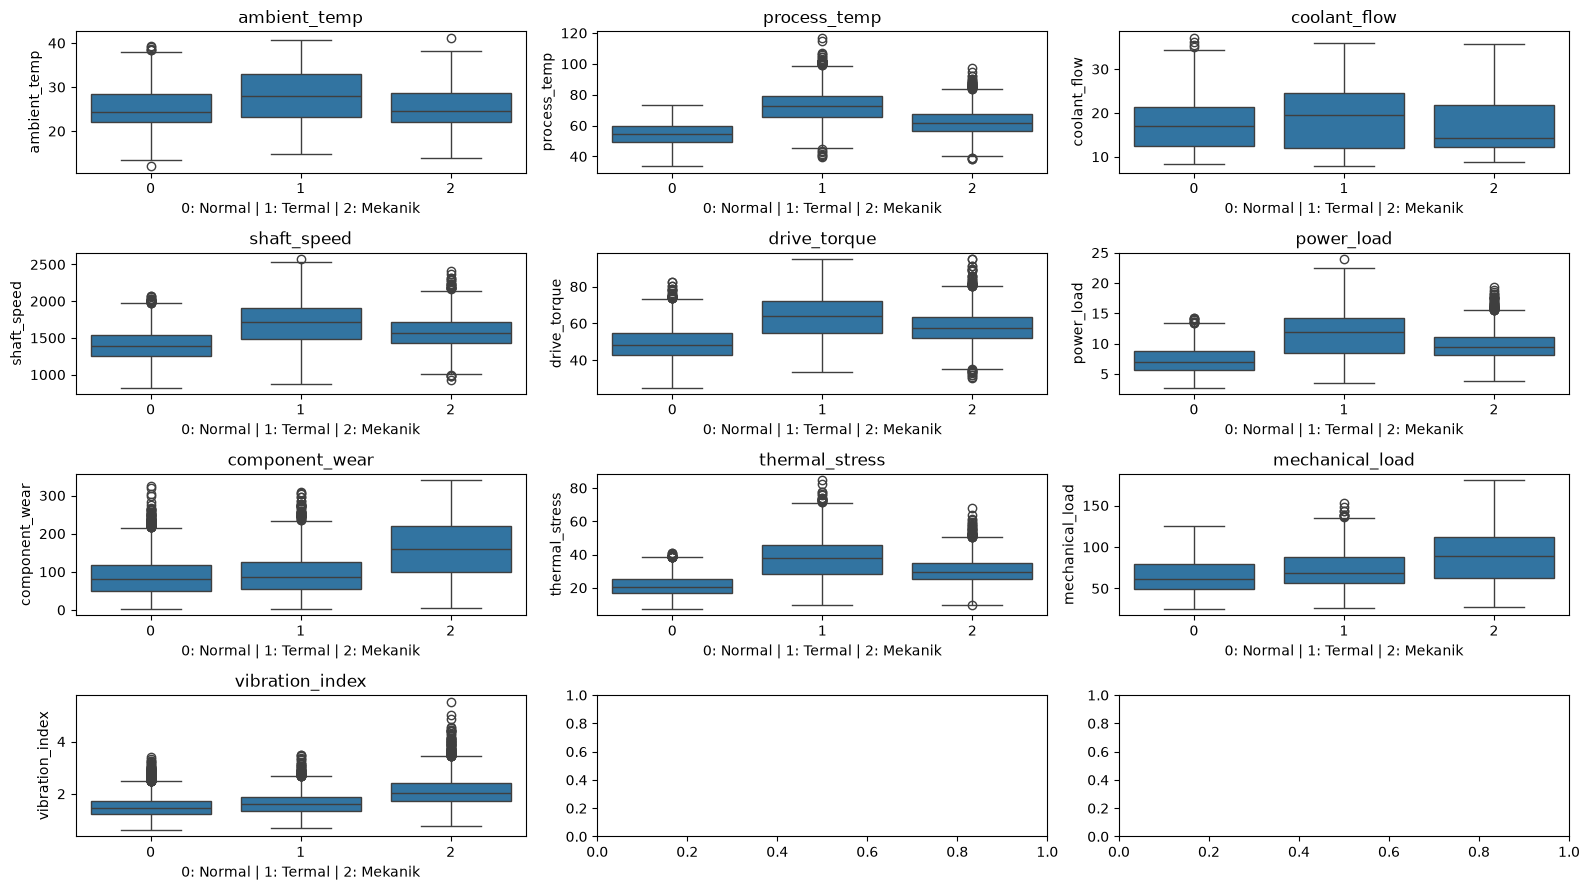

In [8]:
num_cols = raw_data.select_dtypes(include="number").columns.drop(["unit_id","condition"],errors="ignore")

n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axs = plt.subplots(n_rows, n_cols, figsize=(16,9))
axs = axs.ravel()

for i, col in enumerate(num_cols):
    sns.boxplot(data=raw_data, x="condition", y=col, ax=axs[i])
    axs[i].set_title(col)
    axs[i].set_xlabel("0: Normal | 1: Termal | 2: Mekanik")

plt.tight_layout()
plt.show()


In [9]:
import pandas as pd

columns = [
    "process_temp",
    "component_wear",
    "mechanical_load",
    "shaft_speed"
]
rows = []

for col in columns:
    data = raw_data[[col, "condition"]].dropna()

    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    upper_limit = q3 + 1.5 * (q3 - q1)

    high = data[data[col] > upper_limit]
    rest = data[data[col] <= upper_limit]

    high_rates = high["condition"].value_counts(normalize=True)
    rest_rates = rest["condition"].value_counts(normalize=True)

    rows.append({
        "Sütun": col,
        "Maksimum": data[col].max(),
        "Uç değer sınırı": round(upper_limit, 2),
        "Sınırı aşan kayıt": len(high),
        "Sınırı aşan %": round(len(high) / len(data) * 100, 2),
        "Yükseklerde Normal %": round(high_rates.get(0, 0) * 100, 1),
        "Yükseklerde Termal %": round(high_rates.get(1, 0) * 100, 1),
        "Yükseklerde Mekanik %": round(high_rates.get(2, 0) * 100, 1),
        "Diğerlerinde Termal %": round(rest_rates.get(1, 0) * 100, 1),
        "Diğerlerinde Mekanik %": round(rest_rates.get(2, 0) * 100, 1),
    })

display(pd.DataFrame(rows))

,Sütun,Maksimum,Uç değer sınırı,Sınırı aşan kayıt,Sınırı aşan %,Yükseklerde Normal %,Yükseklerde Termal %,Yükseklerde Mekanik %,Diğerlerinde Termal %,Diğerlerinde Mekanik %
0,process_temp,116.90,89.65,222,1.39,0.0,97.3,2.7,24.0,25.3
1,component_wear,340.00,273.00,459,2.88,1.3,2.4,96.3,25.6,22.9
2,mechanical_load,180.42,141.99,91,0.57,0.0,4.4,95.6,25.1,24.6
3,shaft_speed,2574.00,2246.50,88,0.55,0.0,92.0,8.0,24.6,25.1


In [10]:
missing_summary = pd.DataFrame({
    "Missing_Count": raw_data.isnull().sum(),
    "Total_Rows": len(raw_data),
    "Missing_Percentage": (raw_data.isnull().sum() / len(raw_data) * 100)
})

missing_summary = missing_summary[missing_summary["Missing_Count"] > 0]

missing_summary["Missing_Percentage"] = (
    missing_summary["Missing_Percentage"].round(2)
)

missing_summary

,Missing_Count,Total_Rows,Missing_Percentage
unit_type,22,16000,0.14
ambient_temp,47,16000,0.29
process_temp,45,16000,0.28
coolant_flow,61,16000,0.38
shaft_speed,32,16000,0.20
drive_torque,36,16000,0.22
power_load,25,16000,0.16
component_wear,56,16000,0.35
thermal_stress,50,16000,0.31
mechanical_load,45,16000,0.28


In [11]:
missing_rows = raw_data.isnull().any(axis=1).sum()

print("En az 1 missing içeren satır:", missing_rows)
print("Toplam satır:", len(raw_data))
print(f"Silinirse kayıp oranı: %{missing_rows / len(raw_data) * 100:.2f}")

En az 1 missing içeren satır: 240
Toplam satır: 16000
Silinirse kayıp oranı: %1.50


In [12]:
missing_mask = raw_data.isnull().any(axis=1)

missing_vs_complete = pd.crosstab(
    missing_mask,
    raw_data["condition"],
    normalize="index"
) * 100

missing_vs_complete.index = ["Complete", "Has Missing"]

missing_vs_complete.round(2)

condition,0,1,2
Complete,49.99,24.90,25.10
Has Missing,50.42,31.25,18.33


In [13]:
missing_cols = raw_data.columns[raw_data.isnull().any()]

rows = []

for col in missing_cols:
    mask = raw_data[col].isnull()

    target_dist = (
        raw_data.loc[mask, "condition"]
        .value_counts(normalize=True)
        .mul(100)
    )

    rows.append({
        "Feature": col,
        "Missing_Count": mask.sum(),
        "Normal_%": target_dist.get(0, 0),
        "Thermal_%": target_dist.get(1, 0),
        "Mechanical_%": target_dist.get(2, 0)
    })

missing_target_table = pd.DataFrame(rows)

missing_target_table.round(2)


,Feature,Missing_Count,Normal_%,Thermal_%,Mechanical_%
0,unit_type,22,59.09,27.27,13.64
1,ambient_temp,47,51.06,34.04,14.89
2,process_temp,45,46.67,31.11,22.22
3,coolant_flow,61,45.90,27.87,26.23
4,shaft_speed,32,56.25,28.12,15.62
5,drive_torque,36,55.56,33.33,11.11
6,power_load,25,40.00,36.00,24.00
7,component_wear,56,37.50,35.71,26.79
8,thermal_stress,50,48.00,42.00,10.00
9,mechanical_load,45,42.22,40.00,17.78


In [14]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   unit_id          16000 non-null  str    
 1   unit_type        15978 non-null  str    
 2   ambient_temp     15953 non-null  float64
 3   process_temp     15955 non-null  float64
 4   coolant_flow     15939 non-null  float64
 5   shaft_speed      15968 non-null  float64
 6   drive_torque     15964 non-null  float64
 7   power_load       15975 non-null  float64
 8   component_wear   15944 non-null  float64
 9   thermal_stress   15950 non-null  float64
 10  mechanical_load  15955 non-null  float64
 11  vibration_index  15926 non-null  float64
 12  condition        16000 non-null  int64  
dtypes: float64(10), int64(1), str(2)
memory usage: 1.6 MB


In [15]:
X = raw_data.drop(columns=["unit_id", "condition"])
y = raw_data["condition"]

cat_cols = ["unit_type"]
num_cols = X.select_dtypes(include="number").columns.to_list()

print(cat_cols)
print(num_cols)


['unit_type']
['ambient_temp', 'process_temp', 'coolant_flow', 'shaft_speed', 'drive_torque', 'power_load', 'component_wear', 'thermal_stress', 'mechanical_load', 'vibration_index']


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
]
)

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])



In [17]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()

knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", knn)
])

In [18]:
from sklearn.model_selection import StratifiedKFold

stk = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [19]:
from sklearn.model_selection import cross_validate

cv_results = cross_validate(
    knn_pipeline,
    X,
    y,
    cv=stk,
    scoring="accuracy",
    return_train_score=True
)


print("Train Accuracy:", cv_results["train_score"])
print("Validation Accuracy:", cv_results["test_score"])

print("Mean Train Accuracy:", cv_results["train_score"].mean())
print("Mean Validation Accuracy:", cv_results["test_score"].mean())
print("Validation Std:", cv_results["test_score"].std())

Train Accuracy: [0.89164062 0.89367188 0.89273437 0.89046875 0.88992187]
Validation Accuracy: [0.8465625 0.84875   0.855     0.8453125 0.8478125]
Mean Train Accuracy: 0.8916875
Mean Validation Accuracy: 0.8486874999999999
Validation Std: 0.0033622444140781822


In [20]:
from sklearn.model_selection import cross_val_predict

oof_preds = cross_val_predict(
    knn_pipeline,
    X,
    y,
    cv=stk,
    method="predict"
)

In [21]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y, oof_preds))
print(classification_report(y, oof_preds))

[[7590  232  178]
 [ 733 2994  273]
 [ 705  300 2995]]
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      8000
           1       0.85      0.75      0.80      4000
           2       0.87      0.75      0.80      4000

    accuracy                           0.85     16000
   macro avg       0.85      0.82      0.83     16000
weighted avg       0.85      0.85      0.85     16000



In [22]:
xgb_num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

xgb_cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

xgb_preprocessor = ColumnTransformer([
    ("num", xgb_num_pipeline, num_cols),
    ("cat", xgb_cat_pipeline, cat_cols)
])

In [23]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    eval_metric="mlogloss"
)

xgb_pipeline = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("model", xgb)
])



In [24]:
xgb_cv_results = cross_validate(
    xgb_pipeline,
    X,
    y,
    cv=stk,
    scoring="accuracy",
    return_train_score=True
)

print("Train Accuracy:", xgb_cv_results["train_score"])
print("Validation Accuracy:", xgb_cv_results["test_score"])

print("Mean Train Accuracy:", xgb_cv_results["train_score"].mean())
print("Mean Validation Accuracy:", xgb_cv_results["test_score"].mean())
print("Validation Std:", xgb_cv_results["test_score"].std())

Train Accuracy: [0.981875   0.98179688 0.98132812 0.980625   0.9821875 ]
Validation Accuracy: [0.885625  0.8784375 0.8871875 0.8775    0.8784375]
Mean Train Accuracy: 0.9815625000000001
Mean Validation Accuracy: 0.8814375
Validation Std: 0.004101257429130749


In [25]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

xgb_oof_preds = cross_val_predict(
    xgb_pipeline,
    X,
    y,
    cv=stk,
    method="predict"
)

print(confusion_matrix(y, xgb_oof_preds))
print(classification_report(y, xgb_oof_preds))

[[7487  263  250]
 [ 469 3315  216]
 [ 490  209 3301]]
              precision    recall  f1-score   support

           0       0.89      0.94      0.91      8000
           1       0.88      0.83      0.85      4000
           2       0.88      0.83      0.85      4000

    accuracy                           0.88     16000
   macro avg       0.88      0.86      0.87     16000
weighted avg       0.88      0.88      0.88     16000



In [26]:
# Null içeren satırları çıkar
complete_mask = X.notna().all(axis=1)

X_drop = X.loc[complete_mask].copy()
y_drop = y.loc[complete_mask].copy()

print("Original:", len(X))
print("After drop:", len(X_drop))
print("Dropped:", len(X) - len(X_drop))

Original: 16000
After drop: 15760
Dropped: 240


In [27]:
xgb_drop_preprocessor = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

xgb_drop_pipeline = Pipeline([
    ("preprocessor", xgb_drop_preprocessor),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="mlogloss"
    ))
])

In [28]:
xgb_drop_results = cross_validate(
    xgb_drop_pipeline,
    X_drop,
    y_drop,
    cv=stk,
    scoring="accuracy",
    return_train_score=True
)

print("Mean Train Accuracy:", xgb_drop_results["train_score"].mean())
print("Mean Validation Accuracy:", xgb_drop_results["test_score"].mean())
print("Validation Std:", xgb_drop_results["test_score"].std())

Mean Train Accuracy: 0.9822493654822335
Mean Validation Accuracy: 0.8824873096446699
Validation Std: 0.004750839225211906


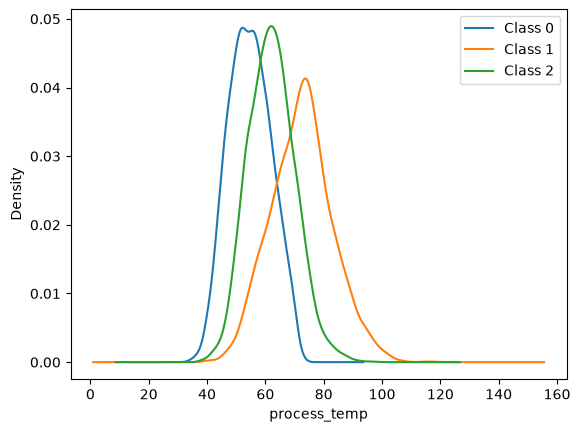

In [29]:

for cls in sorted(raw_data["condition"].unique()):
    raw_data.loc[
        raw_data["condition"] == cls,
        "process_temp"
    ].plot(
        kind="kde",
        label=f"Class {cls}"
    )

plt.legend()
plt.xlabel("process_temp")
plt.show()

In [30]:
from sklearn.feature_selection import mutual_info_classif

X_num = raw_data[num_cols].copy()
X_num = X_num.fillna(X_num.median())

mi = mutual_info_classif(
    X_num,
    raw_data["condition"],
    random_state=42
)

mi_scores = pd.Series(
    mi,
    index=num_cols
).sort_values(ascending=False)

print(mi_scores)

process_temp       0.280927
thermal_stress     0.276711
power_load         0.228147
drive_torque       0.189250
shaft_speed        0.148118
vibration_index    0.131199
component_wear     0.120364
mechanical_load    0.115703
coolant_flow       0.051905
ambient_temp       0.042121
dtype: float64


In [31]:
from scipy.stats import kruskal

for col in num_cols:
    groups = [
        raw_data.loc[
            raw_data["condition"] == cls, col
        ].dropna()
        for cls in sorted(raw_data["condition"].unique())
    ]

    stat, p = kruskal(*groups)

    print(col, p)

ambient_temp 2.8349955048506435e-170
process_temp 0.0
coolant_flow 2.304409301352738e-26
shaft_speed 0.0
drive_torque 0.0
power_load 0.0
component_wear 0.0
thermal_stress 0.0
mechanical_load 0.0
vibration_index 0.0


In [32]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    raw_data["unit_type"],
    raw_data["condition"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("p-value:", p)

p-value: 1.4579108764322115e-174


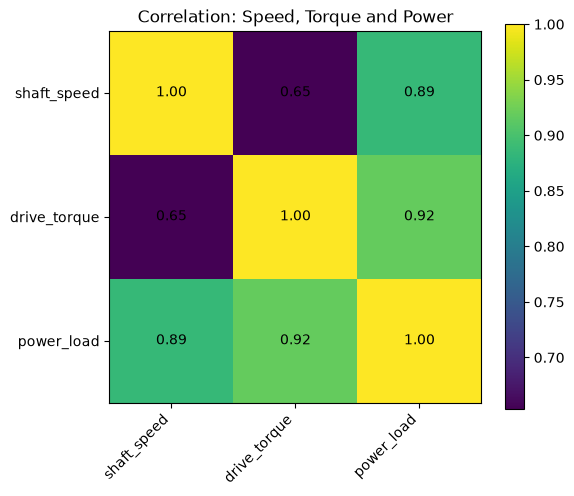

In [33]:
cols = ["shaft_speed", "drive_torque", "power_load"]

import matplotlib.pyplot as plt

corr = raw_data[cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(corr)

ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticklabels(cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation: Speed, Torque and Power")
plt.colorbar(im)
plt.show()

In [34]:
cols = ["shaft_speed", "drive_torque", "power_load"]

raw_data.groupby("condition")[cols].agg(
    ["mean", "median", "std"]
).round(2)

shaft_speed                 drive_torque               power_load  \
                 mean  median     std         mean median    std       mean   
condition                                                                     
0             1399.35  1385.0  205.08        49.13   48.5   8.87       7.30   
1             1697.91  1711.0  285.66        63.93   64.2  11.65      11.60   
2             1580.93  1567.0  214.00        57.94   57.4   8.61       9.65   

                        
          median   std  
condition               
0           6.96  2.10  
1          11.89  3.54  
2           9.40  2.26

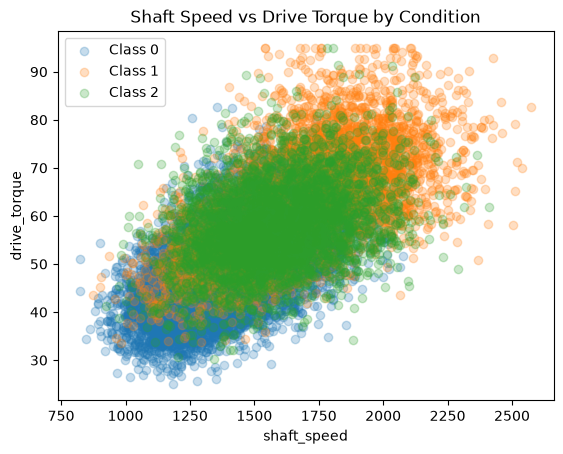

In [35]:
import matplotlib.pyplot as plt

for cls in sorted(raw_data["condition"].unique()):

    subset = raw_data[
        raw_data["condition"] == cls
    ]

    plt.scatter(
        subset["shaft_speed"],
        subset["drive_torque"],
        alpha=0.25,
        label=f"Class {cls}"
    )

plt.xlabel("shaft_speed")
plt.ylabel("drive_torque")
plt.legend()
plt.title("Shaft Speed vs Drive Torque by Condition")
plt.show()

In [36]:
check = raw_data.copy()

check["power_ratio"] = (
    check["power_load"] /
    (check["shaft_speed"] * check["drive_torque"])
)

check.groupby("condition")["power_ratio"].agg(
    ["mean", "median", "std", "min", "max"]
)

,mean,median,std,min,max
condition,,,,,
0,0.000105,0.000105,0.000002,0.000096,0.000112
1,0.000105,0.000105,0.000002,0.000098,0.000113
2,0.000105,0.000105,0.000002,0.000096,0.000112


In [37]:
check = raw_data.copy()

check["temp_rise"] = (
    check["process_temp"] - check["ambient_temp"]
)

check.groupby("condition")["temp_rise"].agg(
    ["mean", "median", "std"]
).round(2)

,mean,median,std
condition,,,
0,29.45,28.7,6.33
1,44.31,44.5,10.50
2,36.79,36.3,7.00


In [38]:
cols = ["thermal_stress", "mechanical_load"]

print(raw_data[cols].corr())

print(
    raw_data.groupby("condition")[cols]
    .agg(["mean", "median", "std"])
    .round(2)
)

                 thermal_stress  mechanical_load
thermal_stress         1.000000         0.044197
mechanical_load        0.044197         1.000000
          thermal_stress               mechanical_load              
                    mean median    std            mean median    std
condition                                                           
0                  21.32  20.54   6.19           64.76  61.89  19.17
1                  37.85  38.08  11.95           72.40  68.37  20.35
2                  30.23  29.77   7.56           88.00  88.64  28.98


In [39]:
check["stress_ratio"] = (
    check["thermal_stress"] /
    (check["mechanical_load"] + 1e-6)
)

check.groupby("condition")["stress_ratio"].agg(
    ["mean", "median", "std"]
).round(3)

,mean,median,std
condition,,,
0,0.364,0.327,0.164
1,0.577,0.583,0.256
2,0.386,0.330,0.168


In [40]:
check["wear_vibration"] = (
    check["component_wear"] *
    check["vibration_index"]
)

check.groupby("condition")["wear_vibration"].agg(
    ["mean", "median", "std"]
).round(2)


,mean,median,std
condition,,,
0,136.09,117.11,91.01
1,158.18,135.64,103.37
2,346.63,312.23,201.06


In [41]:
check = raw_data.copy()

check["thermal_severity"] = (
    check["process_temp"] *
    check["thermal_stress"] /
    (check["coolant_flow"] + 1e-6)
)

check["mechanical_severity"] = (
    check["component_wear"] *
    check["mechanical_load"] *
    check["vibration_index"]
)

check.groupby("condition")[
    ["thermal_severity", "mechanical_severity"]
].agg(["mean", "median", "std"]).round(2)

thermal_severity                mechanical_severity            \
                      mean  median    std                mean    median   
condition                                                                 
0                    71.65   68.41  26.56             9439.01   7069.10   
1                   153.29  144.98  56.23            11893.16   9542.39   
2                   120.49  112.40  51.78            31641.86  25396.12   

                     
                std  
condition            
0           8168.92  
1           9131.45  
2          24393.23